In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/salmansajid05/oral-diseases/Data caries/Data caries/caries orignal data set/done/208.jpg
/kaggle/input/datasets/salmansajid05/oral-diseases/Data caries/Data caries/caries orignal data set/done/45.jpg
/kaggle/input/datasets/salmansajid05/oral-diseases/Data caries/Data caries/caries orignal data set/done/56.jpg
/kaggle/input/datasets/salmansajid05/oral-diseases/Data caries/Data caries/caries orignal data set/done/89.jpg
/kaggle/input/datasets/salmansajid05/oral-diseases/Data caries/Data caries/caries orignal data set/done/20.jpg
/kaggle/input/datasets/salmansajid05/oral-diseases/Data caries/Data caries/caries orignal data set/done/212.jpg
/kaggle/input/datasets/salmansajid05/oral-diseases/Data caries/Data caries/caries orignal data set/done/58.jpg
/kaggle/input/datasets/salmansajid05/oral-diseases/Data caries/Data caries/caries orignal data set/done/150.jpg
/kaggle/input/datasets/salmansajid05/oral-diseases/Data caries/Data caries/caries orignal data set/done/6.jpg

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import tensorflow as tf
import keras
import gradio as gr


from PIL import Image
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [3]:
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [4]:
DATA_DIR = "/kaggle/input/datasets/salmansajid05/oral-diseases"

for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, "").count(os.sep)
    if level > 2:
        dirs[:] = []
        continue
    print("  " * level + os.path.basename(root) + "/")
    if level < 2:
        for file in files[:5]:
            print("  " * (level + 1) + file)

oral-diseases/
  Data caries/
    Data caries/
  Mouth Ulcer/
    Mouth Ulcer/
  Tooth Discoloration/
    Tooth Discoloration /
  hypodontia/
    hypodontia/
  Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/
    Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/
  Gingivitis/
    Gingivitis/
  Calculus/
    Calculus/


In [5]:
DATA_DIR = "/kaggle/input/datasets/salmansajid05/oral-diseases"

for root, dirs, files in os.walk(DATA_DIR):
    images = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    if images:
        print(f"{root}: {len(images)} images")

/kaggle/input/datasets/salmansajid05/oral-diseases/Data caries/Data caries/caries orignal data set/done: 219 images
/kaggle/input/datasets/salmansajid05/oral-diseases/Data caries/Data caries/caries augmented data set/preview: 2382 images
/kaggle/input/datasets/salmansajid05/oral-diseases/Mouth Ulcer/Mouth Ulcer/Mouth_Ulcer_augmented_DataSet/preview: 2541 images
/kaggle/input/datasets/salmansajid05/oral-diseases/Mouth Ulcer/Mouth Ulcer/ulcer original dataset/ulcer original dataset: 265 images
/kaggle/input/datasets/salmansajid05/oral-diseases/Tooth Discoloration/Tooth Discoloration /Tooth_discoloration_augmented_dataser/preview: 1834 images
/kaggle/input/datasets/salmansajid05/oral-diseases/Tooth Discoloration/Tooth Discoloration /tooth discoloration original dataset/tooth discoloration original dataset: 183 images
/kaggle/input/datasets/salmansajid05/oral-diseases/hypodontia/hypodontia: 1251 images
/kaggle/input/datasets/salmansajid05/oral-diseases/Caries_Gingivitus_ToothDiscoloration_

In [6]:
data = [
    ["Calculus", 1296, "Needs inspection"],
    ["Caries", 219, "Original"],
    ["Caries", 2382, "Augmented"],
    ["Gingivitis", 2349, "Needs inspection"],
    ["Mouth Ulcer", 265, "Original"],
    ["Mouth Ulcer", 2541, "Augmented"],
    ["Tooth Discoloration", 183, "Original"],
    ["Tooth Discoloration", 1834, "Augmented"],
    ["Hypodontia", 1251, "Needs inspection"],
    ["YOLO Dataset", 1493, "Train images"],
    ["YOLO Dataset", 49, "Validation images"]
]

df = pd.DataFrame(data, columns=["Class", "Images", "Type"])

display(df)

,Class,Images,Type
0,Calculus,1296,Needs inspection
1,Caries,219,Original
2,Caries,2382,Augmented
3,Gingivitis,2349,Needs inspection
4,Mouth Ulcer,265,Original
5,Mouth Ulcer,2541,Augmented
6,Tooth Discoloration,183,Original
7,Tooth Discoloration,1834,Augmented
8,Hypodontia,1251,Needs inspection
9,YOLO Dataset,1493,Train images


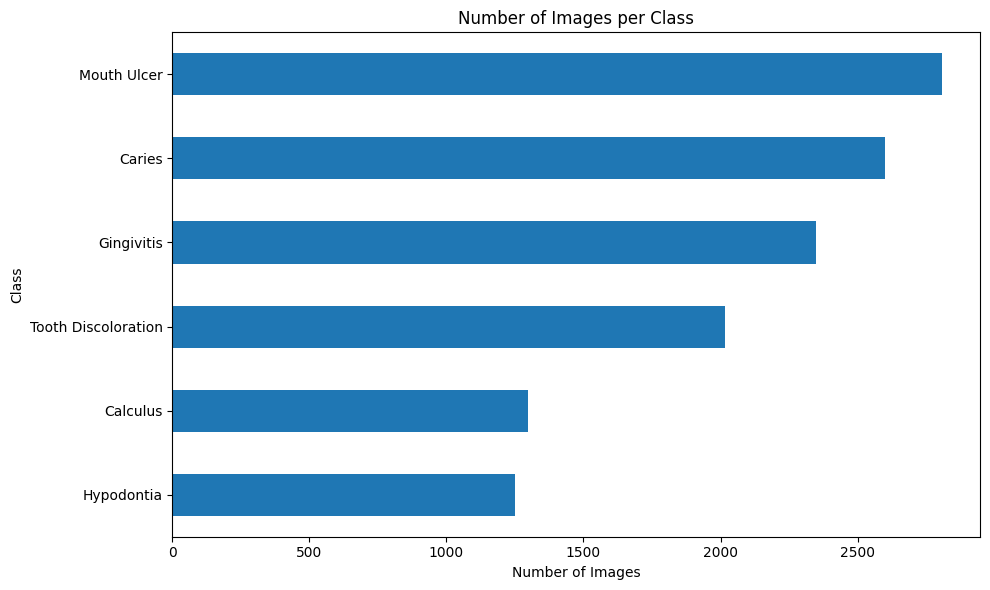

In [7]:
class_counts = df[df["Class"] != "YOLO Dataset"].groupby(
    "Class"
)["Images"].sum().sort_values()

plt.figure(figsize=(10, 6))
class_counts.plot(kind="barh")
plt.title("Number of Images per Class")
plt.xlabel("Number of Images")
plt.ylabel("Class")
plt.tight_layout()
plt.show()

Type,Augmented,Original
Class,,
Caries,2382,219
Mouth Ulcer,2541,265
Tooth Discoloration,1834,183


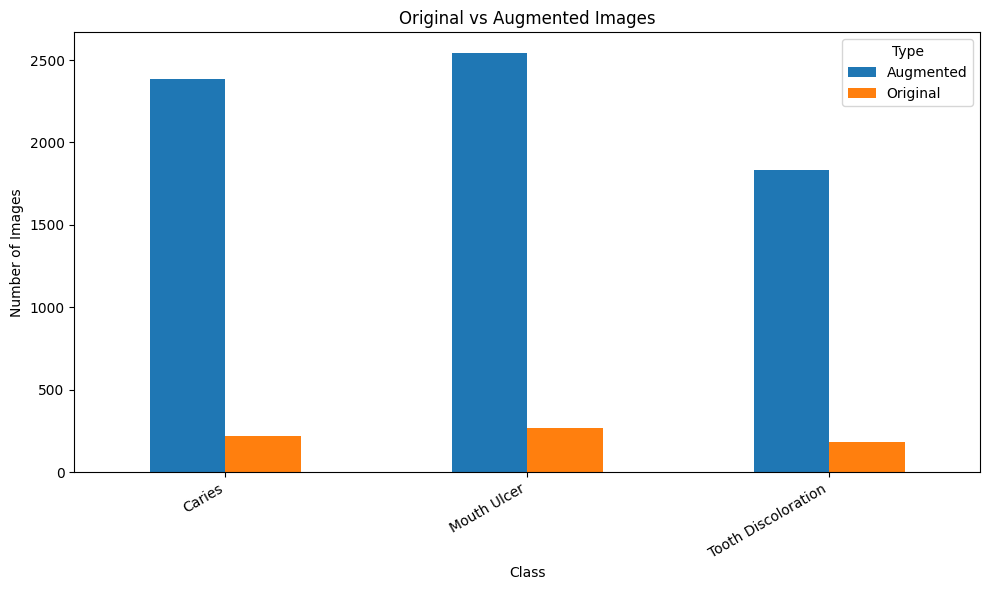

In [8]:
comparison = df[df["Type"].isin(["Original", "Augmented"])].pivot_table(
    index="Class",
    columns="Type",
    values="Images",
    aggfunc="sum",
    fill_value=0
)

display(comparison)

comparison.plot(kind="bar", figsize=(10, 6))
plt.title("Original vs Augmented Images")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

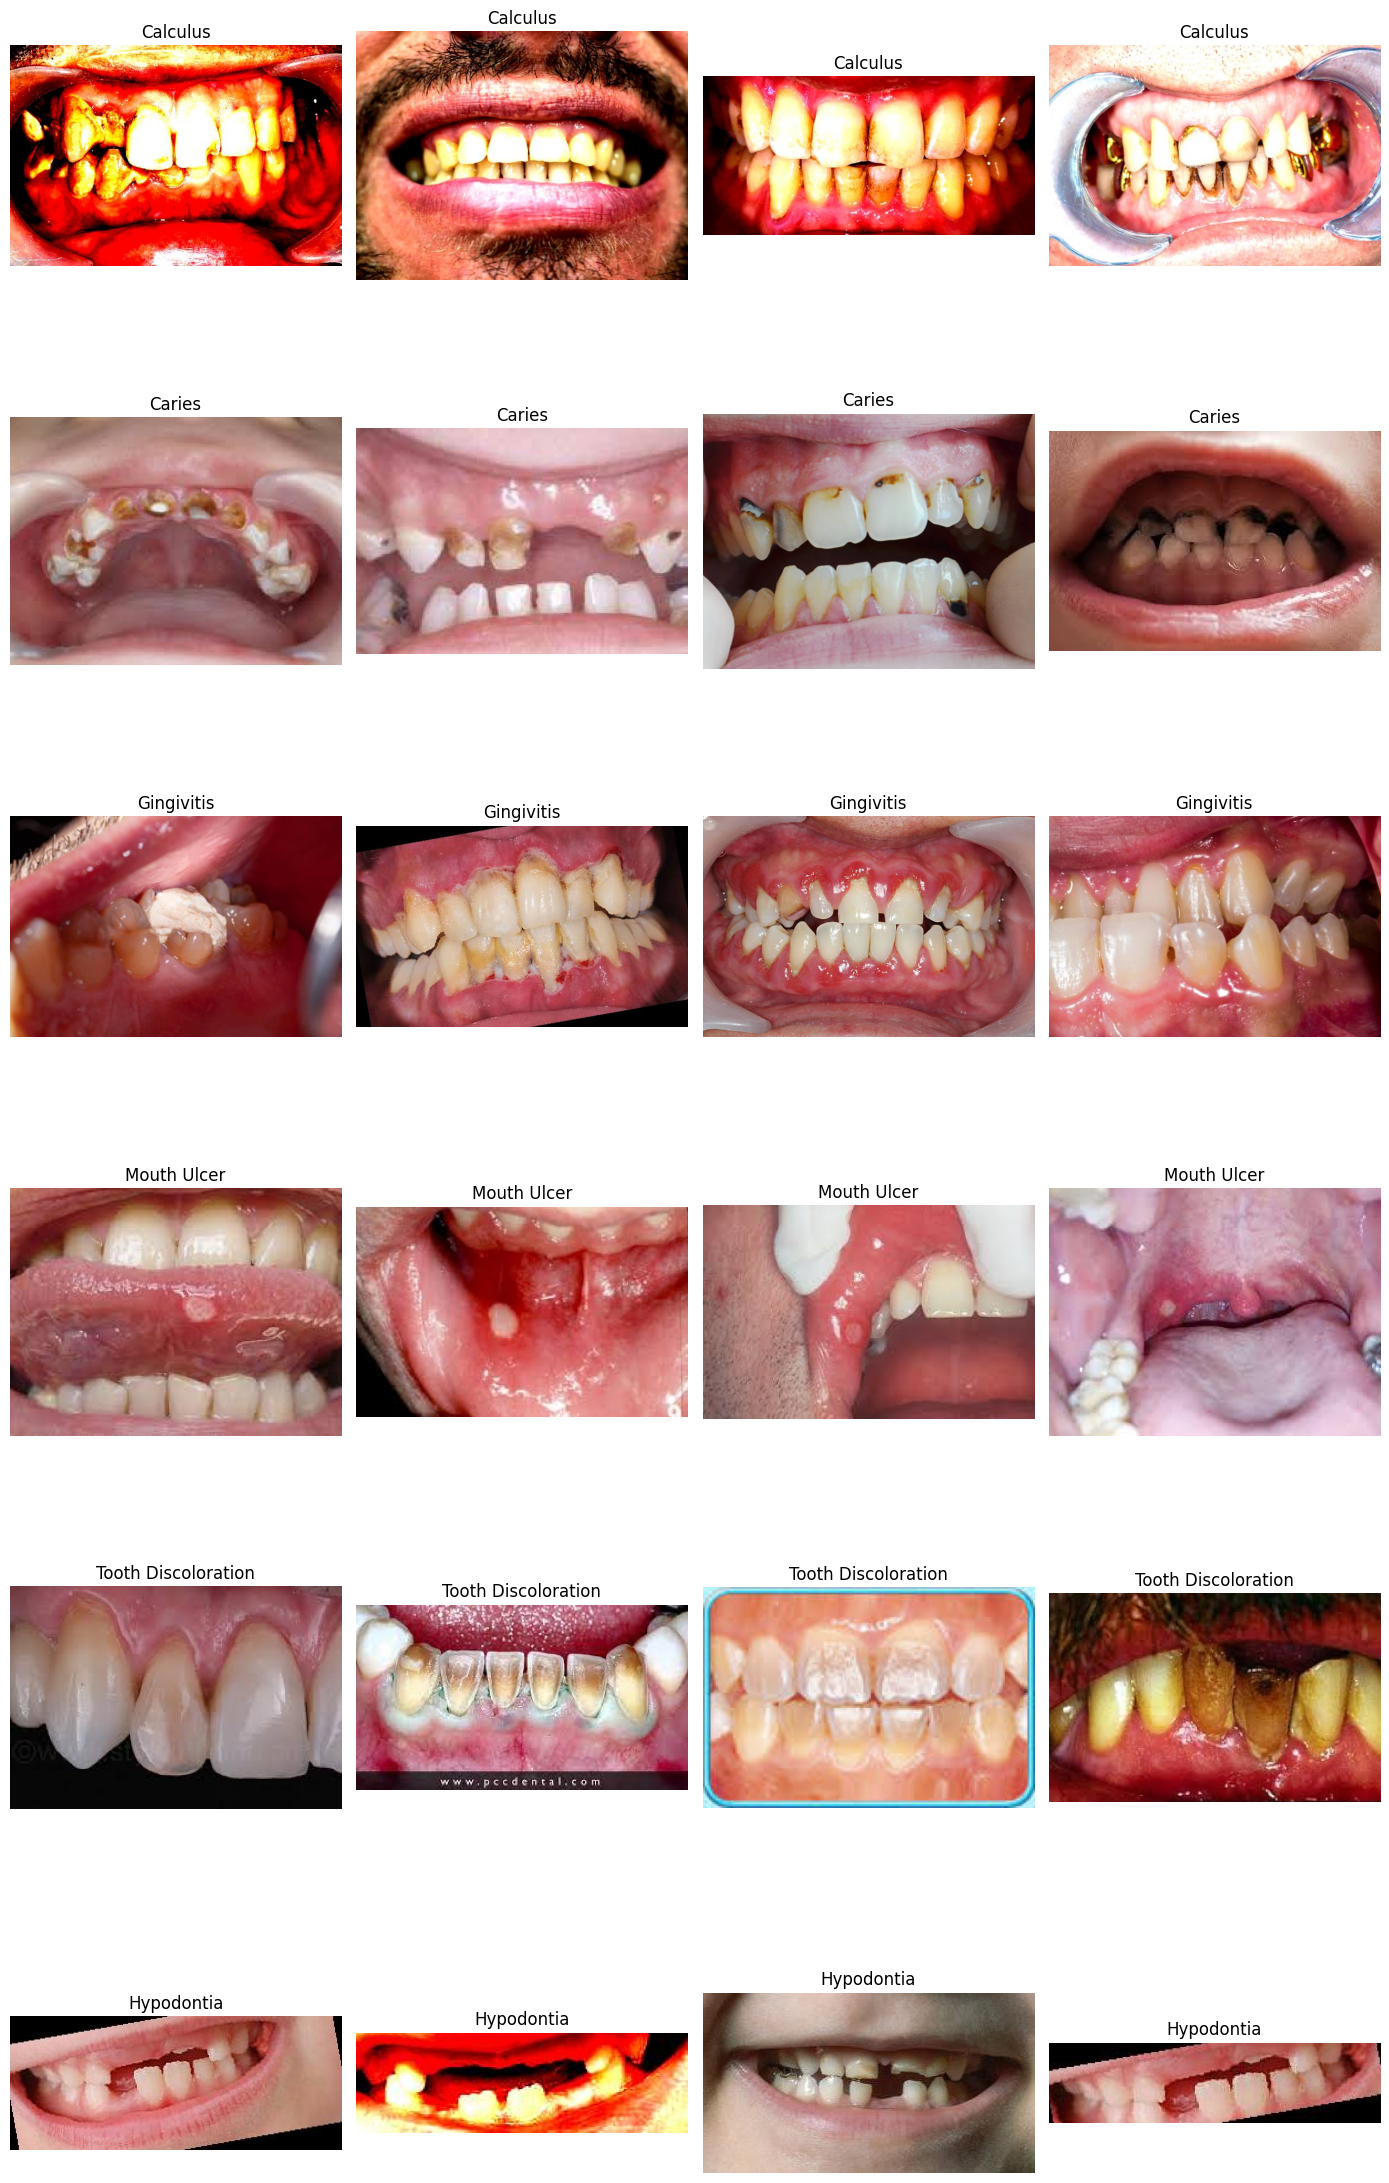

In [9]:
folders = {
    "Calculus": f"{DATA_DIR}/Calculus/Calculus",
    "Caries": f"{DATA_DIR}/Data caries/Data caries/caries orignal data set/done",
    "Gingivitis": f"{DATA_DIR}/Gingivitis/Gingivitis",
    "Mouth Ulcer": f"{DATA_DIR}/Mouth Ulcer/Mouth Ulcer/ulcer original dataset/ulcer original dataset",
    "Tooth Discoloration": f"{DATA_DIR}/Tooth Discoloration/Tooth Discoloration /tooth discoloration original dataset/tooth discoloration original dataset",
    "Hypodontia": f"{DATA_DIR}/hypodontia/hypodontia"
}

extensions = (".jpg", ".jpeg", ".png", ".webp")

fig, axes = plt.subplots(len(folders), 4, figsize=(14, 4 * len(folders)))

for row, (label, folder) in enumerate(folders.items()):
    images = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith(extensions)
    ]

    selected = random.sample(images, min(4, len(images)))

    for col, ax in enumerate(axes[row]):
        ax.axis("off")

        if col < len(selected):
            try:
                img = Image.open(selected[col]).convert("RGB")
                ax.imshow(img)
                ax.set_title(label)
            except Exception:
                ax.set_title("Could not load image")

plt.tight_layout()
plt.show()

In [10]:
classes = {
    "Calculus": os.path.join(DATA_DIR, "Calculus", "Calculus"),
    "Caries": os.path.join(DATA_DIR, "Data caries", "Data caries", "caries orignal data set", "done"),
    "Gingivitis": os.path.join(DATA_DIR, "Gingivitis", "Gingivitis"),
    "Mouth Ulcer": os.path.join(DATA_DIR, "Mouth Ulcer", "Mouth Ulcer", "ulcer original dataset", "ulcer original dataset"),
    "Tooth Discoloration": os.path.join(DATA_DIR, "Tooth Discoloration", "Tooth Discoloration ", "tooth discoloration original dataset", "tooth discoloration original dataset"),
    "Hypodontia": os.path.join(DATA_DIR, "hypodontia", "hypodontia")
}

extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
rows = []

for class_name, folder in classes.items():
    image_count = 0

    if os.path.isdir(folder):
        image_count = sum(
            1
            for file in os.listdir(folder)
            if file.lower().endswith(extensions)
        )

    rows.append({
        "Class": class_name,
        "Folder Exists": os.path.isdir(folder),
        "Original Folder Images": image_count
    })

df_summary = pd.DataFrame(rows)
display(df_summary)


,Class,Folder Exists,Original Folder Images
0,Calculus,True,1296
1,Caries,True,219
2,Gingivitis,True,2349
3,Mouth Ulcer,True,265
4,Tooth Discoloration,True,183
5,Hypodontia,True,1251


In [11]:
extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
results = []

for class_name, folder in classes.items():
    valid = 0
    corrupted = 0

    for file in os.listdir(folder):
        if not file.lower().endswith(extensions):
            continue

        path = os.path.join(folder, file)

        try:
            with Image.open(path) as img:
                img.verify()
            valid += 1
        except Exception:
            corrupted += 1

    results.append({
        "Class": class_name,
        "Valid Images": valid,
        "Corrupted Images": corrupted
    })

display(pd.DataFrame(results))

,Class,Valid Images,Corrupted Images
0,Calculus,1296,0
1,Caries,219,0
2,Gingivitis,2349,0
3,Mouth Ulcer,265,0
4,Tooth Discoloration,183,0
5,Hypodontia,1251,0


In [12]:
import shutil
from pathlib import Path

random.seed(42)

OUTPUT_DIR = "/kaggle/working/oralsense_split"
extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

for split in ["train", "val", "test"]:
    for class_name in classes:
        os.makedirs(
            os.path.join(OUTPUT_DIR, split, class_name),
            exist_ok=True
        )

for class_name, folder in classes.items():
    image_paths = [
        os.path.join(folder, file)
        for file in os.listdir(folder)
        if file.lower().endswith(extensions)
    ]

    random.shuffle(image_paths)

    total = len(image_paths)
    train_end = int(total * 0.70)
    val_end = train_end + int(total * 0.15)

    split_data = {
        "train": image_paths[:train_end],
        "val": image_paths[train_end:val_end],
        "test": image_paths[val_end:]
    }

    for split, paths in split_data.items():
        for i, source in enumerate(paths):
            extension = Path(source).suffix.lower()
            destination = os.path.join(
                OUTPUT_DIR,
                split,
                class_name,
                f"{class_name}_{i}{extension}"
            )
            shutil.copy2(source, destination)

    print(
        f"{class_name}: Train={len(split_data['train'])}, "
        f"Val={len(split_data['val'])}, "
        f"Test={len(split_data['test'])}"
    )

print("Dataset split completed:", OUTPUT_DIR)

Calculus: Train=907, Val=194, Test=195
Caries: Train=153, Val=32, Test=34
Gingivitis: Train=1644, Val=352, Test=353
Mouth Ulcer: Train=185, Val=39, Test=41
Tooth Discoloration: Train=128, Val=27, Test=28
Hypodontia: Train=875, Val=187, Test=189
Dataset split completed: /kaggle/working/oralsense_split


In [13]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(OUTPUT_DIR, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(OUTPUT_DIR, "val"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(OUTPUT_DIR, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 3892 files belonging to 6 classes.


I0000 00:00:1793026378.170248      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793026378.173550      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 831 files belonging to 6 classes.
Found 840 files belonging to 6 classes.
Classes: ['Calculus', 'Caries', 'Gingivitis', 'Hypodontia', 'Mouth Ulcer', 'Tooth Discoloration']
Number of classes: 6


In [14]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1)
])

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6
    ),
    ModelCheckpoint(
        "/kaggle/working/oralsense_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

model.summary()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 18s 85ms/step - accuracy: 0.5850 - loss: 1.1044 - val_accuracy: 0.7268 - val_loss: 0.7152 - learning_rate: 0.0010
Epoch 2/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 8s 69ms/step - accuracy: 0.6822 - loss: 0.7862 - val_accuracy: 0.7425 - val_loss: 0.6880 - learning_rate: 0.0010
Epoch 3/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 9s 72ms/step - accuracy: 0.7153 - loss: 0.6976 - val_accuracy: 0.7437 - val_loss: 0.6472 - learning_rate: 0.0010
Epoch 4/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 8s 66ms/step - accuracy: 0.7220 - loss: 0.6697 - val_accuracy: 0.7329 - val_loss: 0.6807 - learning_rate: 0.0010
Epoch 5/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 9s 71ms/step - accuracy: 0.7418 - loss: 0.6316 - val_accuracy: 0.7533 - val_loss: 0.6077 - learning_rate: 0.0010
Epoch 6/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 9s 72ms/step - accuracy: 0.7533 - loss: 0.6022 - val_accuracy: 0.7653 - val_loss: 0.5991 - learning_rate: 0.0010
Epoch 7/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 8s 67ms/step - accuracy: 0.7495 - loss: 0

In [15]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/oralsense_finetuned.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=fine_tune_callbacks
)

Epoch 1/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 17s 92ms/step - accuracy: 0.7662 - loss: 0.5505 - val_accuracy: 0.7774 - val_loss: 0.5484
Epoch 2/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 10s 80ms/step - accuracy: 0.7891 - loss: 0.5039 - val_accuracy: 0.7750 - val_loss: 0.5380
Epoch 3/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 9s 75ms/step - accuracy: 0.7919 - loss: 0.4899 - val_accuracy: 0.7738 - val_loss: 0.5427
Epoch 4/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 10s 80ms/step - accuracy: 0.8032 - loss: 0.4608 - val_accuracy: 0.7810 - val_loss: 0.5369
Epoch 5/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 10s 81ms/step - accuracy: 0.8191 - loss: 0.4409 - val_accuracy: 0.7894 - val_loss: 0.5171
Epoch 6/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 9s 76ms/step - accuracy: 0.8199 - loss: 0.4271 - val_accuracy: 0.7786 - val_loss: 0.5445
Epoch 7/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 9s 76ms/step - accuracy: 0.8227 - loss: 0.4135 - val_accuracy: 0.7918 - val_loss: 0.5274
Epoch 8/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 10s 80ms/step - accuracy: 0.8297 - loss: 0.3954 - val

In [16]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - accuracy: 0.7798 - loss: 0.5149
Test Loss: 0.5149
Test Accuracy: 77.98%


27/27 ━━━━━━━━━━━━━━━━━━━━ 4s 91ms/step
                     precision    recall  f1-score   support

           Calculus     0.7524    0.4051    0.5267       195
             Caries     0.7895    0.4412    0.5660        34
         Gingivitis     0.6967    0.9433    0.8014       353
         Hypodontia     0.9777    0.9259    0.9511       189
        Mouth Ulcer     0.8837    0.9268    0.9048        41
Tooth Discoloration     0.9375    0.5357    0.6818        28

           accuracy                         0.7798       840
          macro avg     0.8396    0.6964    0.7386       840
       weighted avg     0.7937    0.7798    0.7629       840



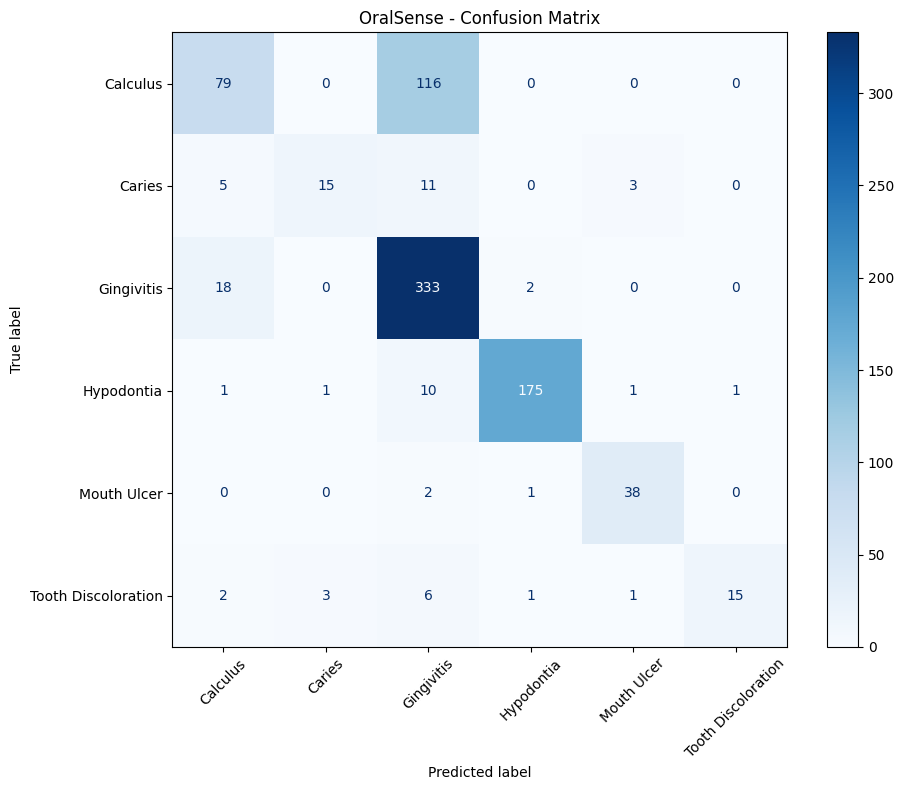

In [17]:
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("OralSense - Confusion Matrix")
plt.tight_layout()
plt.show()


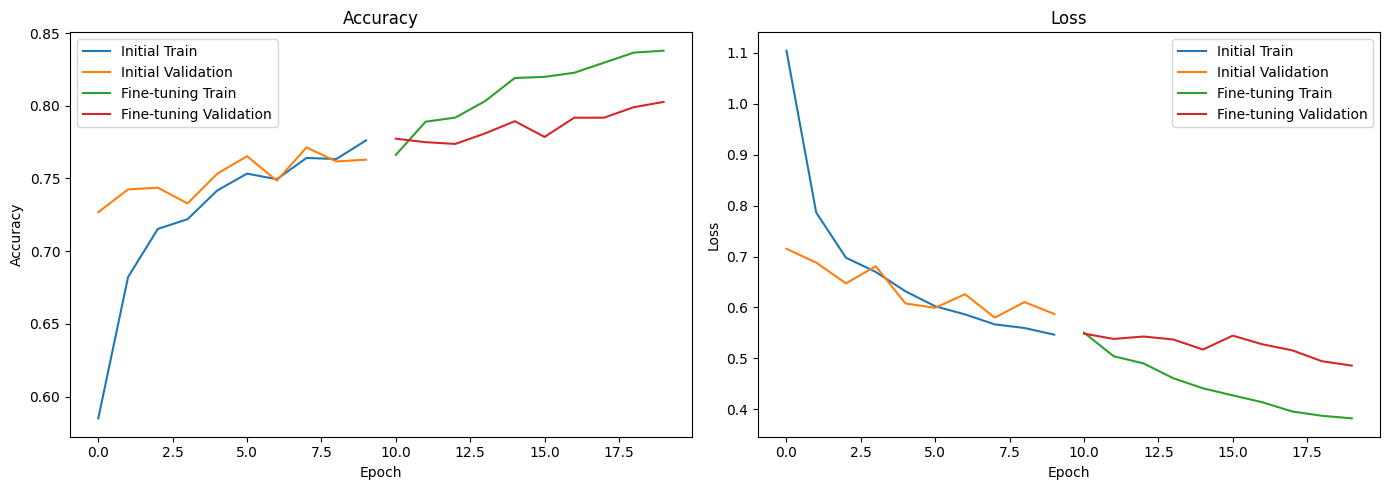

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["accuracy"], label="Initial Train")
axes[0].plot(history.history["val_accuracy"], label="Initial Validation")
axes[0].plot(
    range(len(history.history["accuracy"]),
          len(history.history["accuracy"]) + len(history_fine.history["accuracy"])),
    history_fine.history["accuracy"],
    label="Fine-tuning Train"
)
axes[0].plot(
    range(len(history.history["val_accuracy"]),
          len(history.history["val_accuracy"]) + len(history_fine.history["val_accuracy"])),
    history_fine.history["val_accuracy"],
    label="Fine-tuning Validation"
)
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Initial Train")
axes[1].plot(history.history["val_loss"], label="Initial Validation")
axes[1].plot(
    range(len(history.history["loss"]),
          len(history.history["loss"]) + len(history_fine.history["loss"])),
    history_fine.history["loss"],
    label="Fine-tuning Train"
)
axes[1].plot(
    range(len(history.history["val_loss"]),
          len(history.history["val_loss"]) + len(history_fine.history["val_loss"])),
    history_fine.history["val_loss"],
    label="Fine-tuning Validation"
)
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


* **EfficientNetB0**

In [19]:
efficient_base = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

efficient_base.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = efficient_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.35)(x)
outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

efficient_model = Model(inputs, outputs)

efficient_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficient_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/oralsense_efficientnet_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

efficient_history = efficient_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=efficient_callbacks
)


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/10


E0000 00:00:1793026603.852141      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_2_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


122/122 ━━━━━━━━━━━━━━━━━━━━ 24s 121ms/step - accuracy: 0.5920 - loss: 1.0468 - val_accuracy: 0.6895 - val_loss: 0.7710
Epoch 2/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 12s 97ms/step - accuracy: 0.6906 - loss: 0.7800 - val_accuracy: 0.7292 - val_loss: 0.6734
Epoch 3/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 12s 98ms/step - accuracy: 0.7130 - loss: 0.7125 - val_accuracy: 0.7401 - val_loss: 0.6303
Epoch 4/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 12s 97ms/step - accuracy: 0.7328 - loss: 0.6648 - val_accuracy: 0.7569 - val_loss: 0.5888
Epoch 5/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 12s 96ms/step - accuracy: 0.7418 - loss: 0.6349 - val_accuracy: 0.7665 - val_loss: 0.5810
Epoch 6/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 12s 95ms/step - accuracy: 0.7456 - loss: 0.6223 - val_accuracy: 0.7690 - val_loss: 0.5618
Epoch 7/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 12s 96ms/step - accuracy: 0.7685 - loss: 0.5890 - val_accuracy: 0.7786 - val_loss: 0.5456
Epoch 8/10
122/122 ━━━━━━━━━━━━━━━━━━━━ 11s 90ms/step - accuracy: 0.7626 - loss: 0.5816 - val_accura

In [20]:
y_true_eff = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob_eff = efficient_model.predict(test_ds, verbose=1)
y_pred_eff = np.argmax(y_prob_eff, axis=1)

print("EfficientNetB0 Test Accuracy:",
      round(accuracy_score(y_true_eff, y_pred_eff) * 100, 2), "%")

print("EfficientNetB0 Macro F1:",
      round(f1_score(y_true_eff, y_pred_eff, average="macro") * 100, 2), "%")

print(classification_report(
    y_true_eff,
    y_pred_eff,
    target_names=class_names,
    digits=4,
    zero_division=0
))


27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 159ms/step


NameError: name 'accuracy_score' is not defined

In [ ]:
models = ["MobileNetV2", "EfficientNetB0"]
accuracy = [79.52, 79.40]
macro_f1 = [77.38, 73.55]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(models, accuracy)
ax.set_title("Test Accuracy Comparison")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.bar_label(bars, fmt="%.2f%%", padding=3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(models, macro_f1)
ax.set_title("Macro F1-Score Comparison")
ax.set_ylabel("Macro F1 (%)")
ax.set_ylim(0, 100)
ax.bar_label(bars, fmt="%.2f%%", padding=3)
plt.tight_layout()
plt.show()

classes = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Hypodontia",
    "Mouth Ulcer",
    "Tooth Discoloration"
]

mobilenet_recall = [49.74, 47.06, 90.93, 92.59, 95.12, 71.43]
efficientnet_recall = [53.33, 38.24, 92.07, 91.53, 97.56, 42.86]

x = np.arange(len(classes))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 5))
bars1 = ax.bar(x - width / 2, mobilenet_recall, width, label="MobileNetV2")
bars2 = ax.bar(x + width / 2, efficientnet_recall, width, label="EfficientNetB0")

ax.set_title("Recall Comparison by Class")
ax.set_ylabel("Recall (%)")
ax.set_xticks(x)
ax.set_xticklabels(classes, rotation=25, ha="right")
ax.set_ylim(0, 110)
ax.legend()
ax.bar_label(bars1, fmt="%.1f", padding=2, fontsize=8)
ax.bar_label(bars2, fmt="%.1f", padding=2, fontsize=8)

plt.tight_layout()
plt.show()


In [ ]:
model.save("/kaggle/working/oralsense_model.keras")

print("Model saved successfully!")

In [ ]:
%pip install -q gradio

In [ ]:
PLACEHOLDER = """
<div class="placeholder">
    <div class="ph-icon">🦷</div>
    <div class="ph-title">Your results will appear here</div>
    <div class="ph-text">Upload an oral image and click <b>Analyze Image</b>.</div>
</div>
"""


def bar_color(score):
    if score >= 70:
        return "linear-gradient(90deg,#0891b2,#14b8a6)"
    if score >= 40:
        return "linear-gradient(90deg,#0ea5e9,#6366f1)"
    return "linear-gradient(90deg,#94a3b8,#64748b)"


def build_result_html(names, scores):
    top_name, top_score = names[0], scores[0]

    rows = ""
    for i, (n, s) in enumerate(zip(names, scores)):
        top_cls = " top" if i == 0 else ""
        rows += f"""
        <div class="row{top_cls}">
            <div class="row-head">
                <span class="row-name"><span class="rank">{i + 1}</span>{n}</span>
                <span class="row-score">{s:.2f}%</span>
            </div>
            <div class="track"><div class="fill" style="width:{max(s, 1):.2f}%;background:{bar_color(s)};"></div></div>
        </div>"""

    warn = ""
    if top_score < 50:
        warn = '<div class="warn">⚠️ Low model score — the image may be unclear or outside the training data.</div>'

    return f"""
    <div class="result-card">
        <div class="top-box">
            <div class="top-label">TOP MODEL PREDICTION</div>
            <div class="top-name">{top_name}</div>
            <div class="top-badge">Model score: {top_score:.2f}%</div>
        </div>
        {warn}
        <div class="rows">{rows}</div>
        <div class="note">Educational image classification result — not a medical diagnosis.</div>
    </div>
    """


def predict_oral_disease(image):
    if image is None:
        gr.Warning("Please upload an image first.")
        return PLACEHOLDER, None, None

    image = image.convert("RGB").resize((224, 224))
    image_array = np.array(image, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_array, verbose=0)[0]
    order = np.argsort(probabilities)[::-1]

    names = [class_names[i] for i in order]
    scores = [float(probabilities[i]) * 100 for i in order]

    result_html = build_result_html(names, scores)

    results_df = pd.DataFrame({
        "Rank": range(1, len(names) + 1),
        "Class": names,
        "Model Score (%)": [round(s, 2) for s in scores],
    })

    return result_html, results_df, image


def clear_all():
    return None, PLACEHOLDER, None, None


css = """
:root {
    --os-primary: #0e7490;
    --os-primary-2: #0891b2;
    --os-accent: #14b8a6;
    --os-dark: #164e63;
    --os-soft: #ecfeff;
    --os-border: #cffafe;
}

.gradio-container {
    max-width: 1150px !important;
    margin: auto !important;
    background: linear-gradient(180deg, #f0fdfa 0%, #f8fafc 45%, #eff6ff 100%) !important;
}

/* ---------- Hero ---------- */
.hero {
    text-align: center;
    padding: 38px 20px 34px;
    margin-bottom: 18px;
    border-radius: 20px;
    color: #fff;
    background: linear-gradient(135deg, #164e63 0%, #0e7490 50%, #14b8a6 100%);
    box-shadow: 0 12px 30px rgba(14, 116, 144, .30);
}
.hero h1 { font-size: 2.6rem; font-weight: 800; margin: 0; letter-spacing: .5px; color: #fff; }
.hero p  { margin: 8px 0 0; font-size: 1.05rem; opacity: .92; color: #fff; }
.chips   { margin-top: 16px; display: flex; gap: 10px; justify-content: center; flex-wrap: wrap; }
.chip {
    background: rgba(255,255,255,.18);
    border: 1px solid rgba(255,255,255,.35);
    padding: 5px 14px; border-radius: 999px; font-size: .85rem; color: #fff;
}

/* ---------- Panels ---------- */
.panel {
    background: #ffffff !important;
    border: 1px solid var(--os-border) !important;
    border-radius: 18px !important;
    padding: 18px !important;
    box-shadow: 0 6px 20px rgba(15, 23, 42, .06);
}
.panel-title { color: var(--os-dark); font-weight: 700; font-size: 1.1rem; margin-bottom: 4px; }

/* ---------- Buttons ---------- */
#analyze-btn {
    background: linear-gradient(135deg, #0891b2, #14b8a6) !important;
    border: none !important; color: #fff !important;
    font-weight: 700 !important; font-size: 1rem !important;
    border-radius: 12px !important;
    box-shadow: 0 6px 16px rgba(8,145,178,.35);
    transition: transform .15s ease, box-shadow .15s ease;
}
#analyze-btn:hover { transform: translateY(-2px); box-shadow: 0 10px 22px rgba(8,145,178,.45); }
#clear-btn {
    border-radius: 12px !important; font-weight: 600 !important;
    border: 1.5px solid var(--os-primary-2) !important;
    color: var(--os-primary) !important; background: #fff !important;
}
#clear-btn:hover { background: var(--os-soft) !important; }

/* ---------- Result card ---------- */
.placeholder { text-align: center; padding: 50px 10px; color: #64748b; }
.ph-icon  { font-size: 3rem; }
.ph-title { font-weight: 700; color: var(--os-dark); margin-top: 8px; font-size: 1.1rem; }
.ph-text  { margin-top: 4px; }

.top-box {
    text-align: center; padding: 20px 14px; border-radius: 16px;
    background: linear-gradient(135deg, #ecfeff, #f0fdfa);
    border: 1px solid var(--os-border);
}
.top-label { font-size: .75rem; letter-spacing: 2px; color: #0e7490; font-weight: 700; }
.top-name  { font-size: 1.8rem; font-weight: 800; color: var(--os-dark); margin: 6px 0 10px; }
.top-badge {
    display: inline-block; padding: 6px 18px; border-radius: 999px;
    background: linear-gradient(135deg, #0891b2, #14b8a6);
    color: #fff; font-weight: 700; font-size: .95rem;
}
.warn {
    margin-top: 12px; padding: 10px 14px; border-radius: 10px;
    background: #fffbeb; border: 1px solid #fde68a; color: #92400e; font-size: .9rem;
}
.rows { margin-top: 16px; display: flex; flex-direction: column; gap: 12px; }
.row-head { display: flex; justify-content: space-between; margin-bottom: 5px; color: #334155; font-size: .95rem; }
.row.top .row-name { font-weight: 700; color: var(--os-dark); }
.rank {
    display: inline-flex; align-items: center; justify-content: center;
    width: 22px; height: 22px; margin-right: 8px; border-radius: 50%;
    background: #e0f2fe; color: #0369a1; font-size: .75rem; font-weight: 700;
}
.row.top .rank { background: #0891b2; color: #fff; }
.row-score { font-weight: 700; color: #0e7490; }
.track { height: 10px; background: #e2e8f0; border-radius: 999px; overflow: hidden; }
.fill  { height: 100%; border-radius: 999px; transition: width .6s ease; }
.note  { margin-top: 16px; font-size: .8rem; color: #64748b; text-align: center; }

/* ---------- Footer ---------- */
.disclaimer {
    margin-top: 14px; padding: 14px 18px; border-radius: 14px;
    background: #fff7ed; border: 1px solid #fed7aa; color: #9a3412; font-size: .9rem;
}
"""

theme = gr.themes.Soft(
    primary_hue="cyan",
    secondary_hue="teal",
    neutral_hue="slate",
    font=[gr.themes.GoogleFont("Inter"), "ui-sans-serif", "system-ui", "sans-serif"],
)

with gr.Blocks(theme=theme, css=css, title="OralSense | AI Image Analysis") as demo:

    gr.HTML("""
    <div class="hero">
        <h1>🦷 OralSense</h1>
        <p>AI-Powered Oral Image Classification</p>
        <div class="chips">
            <span class="chip">Deep Learning</span>
            <span class="chip">6 Image Categories</span>
            <span class="chip">Educational Use</span>
        </div>
    </div>
    """)

    with gr.Row(equal_height=True):
        with gr.Column(scale=1, elem_classes="panel"):
            gr.HTML('<div class="panel-title">📤 Upload Image</div>')
            image_input = gr.Image(
                type="pil",
                label="Oral Image",
                height=330,
                sources=["upload", "clipboard"],
            )
            with gr.Row():
                analyze_button = gr.Button("🔍 Analyze Image", elem_id="analyze-btn", scale=2)
                clear_button = gr.Button("Clear", elem_id="clear-btn", scale=1)

        with gr.Column(scale=1, elem_classes="panel"):
            gr.HTML('<div class="panel-title">📊 Prediction</div>')
            prediction_output = gr.HTML(PLACEHOLDER)

    with gr.Row():
        with gr.Column(scale=1, elem_classes="panel"):
            image_preview = gr.Image(
                label="Processed Image (224×224)",
                interactive=False,
                height=260,
            )
        with gr.Column(scale=1, elem_classes="panel"):
            results_table = gr.Dataframe(
                headers=["Rank", "Class", "Model Score (%)"],
                datatype=["number", "str", "number"],
                label="Prediction Scores",
                interactive=False,
            )

    gr.HTML("""
    <div class="disclaimer">
        <b>Disclaimer:</b> This application is for educational and research purposes only.
        Model scores are not calibrated medical probabilities and must not be used as a diagnosis.
    </div>
    """)

    analyze_button.click(
        fn=predict_oral_disease,
        inputs=image_input,
        outputs=[prediction_output, results_table, image_preview],
    )

    clear_button.click(
        fn=clear_all,
        inputs=None,
        outputs=[image_input, prediction_output, results_table, image_preview],
    )

demo.launch(share=True)